# Pick and place with a planar robot arm: massively parallel RL on a Colab T4

A 2D arm (side view, gravity on) has to **pick an object up off the ground, carry it, and put it down at a goal**. Thousands of arms train in parallel on the GPU.

- **Gripper**: suction-style. One extra action opens or closes it. Closing it with the fingertip on the object attaches the object; opening it lets go. Finger contact forces are not simulated.
- **Payload**: while held, the object's mass is added to the arm's dynamics, so the arm has to work harder and swings differently. A released object falls under gravity (keeping the fingertip's velocity) and stays where it lands.
- **Two kinds of start, in equal numbers**: half of the environments always start with the **object on the ground**, the other half with the **arm already holding it**.

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

In [7]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU found - this will be slow")

N_LINKS = 3
RESET_MODE = "original"    # "omni": OmniReset-style starts.  "original": half on the ground, half holding
SAMPLER = "sgs"            # "uniform": a fresh random start at every reset.  "sgs": success guided sampling

device: cuda | Tesla T4


## 1. The simulation

**Scene.** The arm's base is at the origin, 0.5 m above the ground. Link angles `θ` are absolute, measured from straight up. The object is a small disc resting on the ground at a random `x`; the goal is another random spot on the ground.

**Everything about one batch of arms lives in a dictionary** `st`:

| key | meaning |
|---|---|
| `q` | arm state `[θ1…θk, ω1…ωk]` |
| `obj`, `obj_v` | object position and velocity |
| `held` | is the object attached to the fingertip? |
| `closed` | was the gripper closed on the previous step? |
| `goal_x` | where on the ground the object should end up |
| `mass` | object mass (random per episode) |

**Action**: `k` joint torques in `[-1, 1]` (scaled by each joint's torque limit) plus one gripper command (**> 0 = closed**).

**Gripper rules**
- *Grasp*: happens on the step the gripper goes from open to closed, if the fingertip is within `grasp_radius` of the object. Arriving with the gripper already closed does nothing.
- *Release*: happens as soon as the command goes to open.

**Reward** per step is a ladder, so each stage is worth more than the one before:

| situation | reward |
|---|---|
| object free: move fingertip to it | 0 … 0.5 (closer is better) |
| object held: carry it to the goal | 0.5 … 1.5 (closer is better) |
| object resting on the goal, released | 2.0 |

minus small costs for torque, joint speed, any part of the arm dipping below ground level (the ground does not physically stop the arm), and a small **grip cost** for keeping the gripper closed. The grip cost matters: without it the policy has no reason to ever try letting go, and gets stuck holding the object over the goal forever.

**Episode**: 5 seconds, never ends early. **Success** = the object is resting on the goal, released, for the whole final half-second.

In [8]:
class PickPlaceArm:
    def __init__(self, num_envs, device, n_links=2, dt=0.02, substeps=2, max_steps=250,
                 m_link=0.5, l_link=0.5, g=9.81, joint_damping=0.1, torque_factor=3.0,
                 ground_y=-0.5, obj_radius=0.04,
                 x_range=0.75,                 # object and goal x are drawn from +/- this (m)
                 min_separation=0.2,           # ground starts: goal at least this far from the object (m)
                 obj_mass=(0.1, 0.3),          # object mass range (kg)
                 init_w=1.0,                   # initial joint speeds within +/- this (rad/s)
                 grasp_radius=0.05, tol=0.05,  # grasp reach, and how close to the goal counts as placed (m)
                 grip_cost=0.05,

                 reset_mode="original",          # "original" or "omni"
                 omni_weights=(1, 1, 1, 1),      # relative frequency: reaching, near-object, grasped, near-goal
                 near_offset=0.08,               # near-object / near-goal: max fingertip distance from the object (m)
                 near_goal_dx=0.15,              # near-goal: object within this distance sideways of the goal (m)
                 near_goal_dy=0.15,              # near-goal: object up to this height above the ground (m)
                 air_height=0.5,                 # grasped: highest object position (m)
                 contact_w=0.2,                  # joint speeds within +/- this for the three non-reaching regions (rad/s)

                 sampler="uniform",            # "uniform" or "sgs" (success guided sampling)
                 sgs_configs=4096,             # N: size of the fixed set of start configurations
                 sgs_history=100,              # H: outcomes remembered per configuration
                 sgs_target=0.5,               # t: success rate that gets sampled most often
                 sgs_kappa=1.0,                # kappa: how sharply sampling focuses on the target
                 sgs_temperature=2.0,          # T: softmax temperature (values below 1 are treated as 1)
                 sgs_eps=1e-4,
                 hold_time=0.5):               # success = object placed for this long at the end of the episode (s)

        self.n, self.device, self.k = num_envs, device, n_links
        self.dt, self.substeps, self.max_steps = dt, substeps, max_steps
        self.g, self.d_j = g, joint_damping
        self.ground_y, self.obj_radius, self.rest_y = ground_y, obj_radius, ground_y + obj_radius
        self.x_range, self.min_separation, self.obj_mass, self.init_w = x_range, min_separation, obj_mass, init_w
        self.grasp_radius, self.tol, self.grip_cost = grasp_radius, tol, grip_cost

        assert reset_mode in ("original", "omni")
        self.reset_mode, self.omni_weights = reset_mode, omni_weights
        self.near_offset, self.near_goal_dx, self.near_goal_dy = near_offset, near_goal_dx, near_goal_dy
        self.air_height, self.contact_w = air_height, contact_w

        assert sampler in ("uniform", "sgs")
        self.sampler = sampler
        self.sgs_configs, self.sgs_history = sgs_configs, sgs_history
        self.sgs_target, self.sgs_kappa, self.sgs_temperature, self.sgs_eps = sgs_target, sgs_kappa, sgs_temperature, sgs_eps
        self.hold_steps = int(round(hold_time / dt))

        k = n_links
        self.obs_dim, self.act_dim = 3 * k + 7, k + 1

        # Constant coefficients of the Lagrangian (uniform rods, centre of mass at mid-length).
        m, l = np.full(k, float(m_link)), np.full(k, float(l_link))
        a, J = l / 2, m * l**2 / 12
        above = np.array([m[i + 1:].sum() for i in range(k)])      # mass carried beyond link i
        B = m * a + l * above
        C = np.zeros((k, k))
        for i in range(k):
            C[i, i] = m[i] * a[i]**2 + J[i] + l[i]**2 * above[i]
            for j in range(i + 1, k):
                C[i, j] = C[j, i] = l[i] * B[j]
        # Torque needed at joint j to hold the (empty) arm stretched out horizontally.
        hold = np.array([g * sum(m[i] * (l[j:i].sum() + a[i]) for i in range(j, k)) for j in range(k)])

        f32 = lambda x: torch.tensor(x, dtype=torch.float32, device=device)
        self.l, self.length = l.tolist(), float(l.sum())
        self.l_t, self.B0, self.C0 = f32(l), f32(B), f32(C)
        self.llT = f32(np.outer(l, l))            # how a point mass at the fingertip adds to the mass matrix
        self.tau_max = f32(torque_factor * hold)

        # Half of the environments always restart holding the object, half with it on the ground.
        # Every episode lasts exactly max_steps, so the two kinds of reset occur in equal numbers.
        self.start_holding = torch.arange(num_envs, device=device) % 2 == 1
        self.placed_steps = torch.zeros(num_envs, dtype=torch.long, device=device)   # consecutive steps placed
        self.ep_steps = torch.zeros(num_envs, dtype=torch.long, device=device)       # steps since episode began
        self.cfg_idx = torch.zeros(num_envs, dtype=torch.long, device=device)        # which SGS configuration
        if sampler == "sgs":
            self.build_sgs()
        self.st = self.next_starts(torch.arange(num_envs, device=device))
        self.t = torch.zeros(num_envs, dtype=torch.long, device=device)

    # ---------- physics ----------
    def deriv(self, q, cmd, payload):
        # payload: mass currently attached to the fingertip (0 when nothing is held), shape (n,)
        k = self.k
        th, w = q[:, :k], q[:, k:]
        dth = th.unsqueeze(2) - th.unsqueeze(1)                    # dth[n, i, j] = th_i - th_j
        C = self.C0 + payload.view(-1, 1, 1) * self.llT
        B = self.B0 + payload.view(-1, 1) * self.l_t
        rel_w = w - torch.cat([torch.zeros_like(w[:, :1]), w[:, :-1]], dim=1)
        u = cmd * self.tau_max - self.d_j * rel_w                                # motor + friction at each joint
        Q = u - torch.cat([u[:, 1:], torch.zeros_like(u[:, :1])], dim=1)         # joint torques -> forces on link angles
        rhs = -(C * torch.sin(dth) * (w**2).unsqueeze(1)).sum(-1) + self.g * B * torch.sin(th) + Q
        qdd = torch.linalg.solve(C * torch.cos(dth), rhs.unsqueeze(-1)).squeeze(-1)
        return torch.cat([w, qdd], dim=1)

    def physics_step(self, q, cmd, payload):
        dt = self.dt / self.substeps
        for _ in range(self.substeps):                             # RK4
            k1 = self.deriv(q, cmd, payload)
            k2 = self.deriv(q + 0.5 * dt * k1, cmd, payload)
            k3 = self.deriv(q + 0.5 * dt * k2, cmd, payload)
            k4 = self.deriv(q + dt * k3, cmd, payload)
            q = q + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        return q

    def tip(self, q):
        th = q[:, :self.k]
        return torch.stack([(self.l_t * torch.sin(th)).sum(-1), (self.l_t * torch.cos(th)).sum(-1)], dim=1)

    def tip_velocity(self, q):
        th, w = q[:, :self.k], q[:, self.k:]
        return torch.stack([(self.l_t * w * torch.cos(th)).sum(-1), -(self.l_t * w * torch.sin(th)).sum(-1)], dim=1)

    # ---------- task definition ----------
    def sample(self, n, holding, mass=None):
        # Random starts for n arms. holding: bool tensor (n,), True = start with the object in the gripper.
        k, dev = self.k, self.device
        u = lambda *shape: torch.rand(*shape, device=dev) * 2 - 1              # uniform in [-1, 1]
        joint = torch.cat([u(n, 1) * 0.6 * math.pi, u(n, k - 1) * 0.8 * math.pi], dim=1)
        th = torch.cumsum(joint, dim=1)
        # If the fingertip would start too close to the ground, lay the outer links horizontal instead.
        low = (self.l_t * torch.cos(th)).sum(-1) < self.ground_y + 0.1
        side = torch.where(joint[:, 1:2] >= 0, 1.0, -1.0) * math.pi / 2
        th[:, 1:] = torch.where(low.unsqueeze(1), side.expand(-1, k - 1), th[:, 1:])
        q = torch.cat([th, u(n, k) * self.init_w], dim=1)

        obj_x, goal_x = u(n) * self.x_range, u(n) * self.x_range
        for _ in range(20):                                        # redraw goals that are too close to the object
            bad = ((goal_x - obj_x).abs() < self.min_separation) & ~holding
            goal_x = torch.where(bad, u(n) * self.x_range, goal_x)
        if mass is None:
            lo, hi = self.obj_mass
            mass = lo + torch.rand(n, device=dev) * (hi - lo)
        obj = torch.stack([obj_x, torch.full_like(obj_x, self.rest_y)], dim=1)
        obj = torch.where(holding.unsqueeze(1), self.tip(q), obj)
        return {"q": q, "obj": obj, "obj_v": torch.zeros(n, 2, device=dev),
                "held": holding.clone(), "closed": holding.clone(), "goal_x": goal_x, "mass": mass}

    def sample_reset(self, idx):
        # Start states for the environments in idx, according to reset_mode.
        if self.reset_mode == "omni":
            return self.sample_omni(idx.numel())
        return self.sample(idx.numel(), self.start_holding[idx])

    def place_tip(self, p, tries=20):
        # Random arm poses (absolute link angles, shape (n, k)) with the fingertip exactly at p (n, 2).
        # The first k-2 links get random angles; the last two are solved by 2-link inverse kinematics
        # from the end of link k-2, with a random elbow side. Rows where the target is out of reach,
        # or a joint would be at or below the ground, are redrawn.
        k, dev, n = self.k, self.device, p.shape[0]
        l = self.l_t
        l1, l2 = self.l[-2], self.l[-1]
        th = torch.zeros(n, k, device=dev)
        todo = torch.ones(n, dtype=torch.bool, device=dev)
        for i in range(tries):
            cand = torch.zeros(n, k, device=dev)
            if k > 2:
                joint = (torch.rand(n, k - 2, device=dev) * 2 - 1) * math.pi
                joint[:, 1:] *= 0.9
                cand[:, :k - 2] = torch.cumsum(joint, dim=1)
            inner = cand[:, :k - 2]
            base = torch.stack([(l[:k - 2] * torch.sin(inner)).sum(-1), (l[:k - 2] * torch.cos(inner)).sum(-1)], dim=1)
            d = p - base
            r = d.norm(dim=1)
            reachable = (r <= l1 + l2) & (r >= abs(l1 - l2))
            c2 = ((r**2 - l1**2 - l2**2) / (2 * l1 * l2)).clamp(-1.0, 1.0)
            q2 = torch.where(torch.rand(n, device=dev) < 0.5, 1.0, -1.0) * torch.acos(c2)
            a = torch.atan2(d[:, 0], d[:, 1]) - torch.atan2(l2 * torch.sin(q2), l1 + l2 * torch.cos(q2))
            cand[:, k - 2], cand[:, k - 1] = a, a + q2
            joints_y = torch.cumsum(l * torch.cos(cand), dim=1)
            ok = todo & reachable & (joints_y[:, :-1] > self.ground_y + 0.05).all(dim=1)
            if i == tries - 1:
                ok = todo                      # last try: accept whatever is left
            th[ok] = cand[ok]
            todo &= ~ok
            if not todo.any():
                break
        return th

    def sample_workspace_points(self, n):
        # Uniform points with |x| <= x_range, from resting on the ground up to air_height,
        # within 95% of full reach (rejection sampling).
        dev = self.device
        pts = torch.zeros(n, 2, device=dev)
        todo = torch.ones(n, dtype=torch.bool, device=dev)
        for _ in range(20):
            cand = torch.stack([(torch.rand(n, device=dev) * 2 - 1) * self.x_range,
                                self.rest_y + torch.rand(n, device=dev) * (self.air_height - self.rest_y)], dim=1)
            ok = todo & (cand.norm(dim=1) <= 0.95 * self.length)
            pts[ok] = cand[ok]
            todo &= ~ok
            if not todo.any():
                break
        return pts

    def sample_omni(self, n):
        # OmniReset-style starts (Yin et al., 2026). Each start comes from one of four regions:
        #   0 reaching:    object on the ground, arm in a random pose (= the original ground start)
        #   1 near object: object on the ground, fingertip close to it, gripper randomly open/closed, not held
        #   2 grasped:     object held, anywhere in the workspace including in the air
        #   3 near goal:   object a small offset from the goal (maybe in the air), fingertip on it, held or not
        dev = self.device
        w = torch.tensor(self.omni_weights, dtype=torch.float32, device=dev)
        region = torch.multinomial(w / w.sum(), n, replacement=True)
        self.last_region = region                                  # kept for diagnostics
        r1, r2, r3 = region == 1, region == 2, region == 3

        # The original sampler gives region 0 as is, plus the goal and object mass for every region.
        st = self.sample(n, torch.zeros(n, dtype=torch.bool, device=dev))

        # where the object goes
        near_goal = torch.stack([st["goal_x"] + (torch.rand(n, device=dev) * 2 - 1) * self.near_goal_dx,
                                 self.rest_y + torch.rand(n, device=dev) * self.near_goal_dy], dim=1)
        obj = torch.where(r2.unsqueeze(1), self.sample_workspace_points(n), st["obj"])
        obj = torch.where(r3.unsqueeze(1), near_goal, obj)

        # whether it is held, and where the fingertip goes: on the object if held, else a small random offset
        held = r2 | (r3 & (torch.rand(n, device=dev) < 0.5))
        phi = torch.rand(n, device=dev) * 2 * math.pi
        rad = torch.rand(n, device=dev) * self.near_offset * (~held)
        tip_target = obj + rad.unsqueeze(1) * torch.stack([torch.cos(phi), torch.sin(phi)], dim=1)
        tip_target = torch.stack([tip_target[:, 0], tip_target[:, 1].clamp(min=self.ground_y + 0.01)], dim=1)

        # arm pose by inverse kinematics: random elbow side, flipped if the elbow would be at or below the ground
        th = self.place_tip(tip_target)
        w0 = (torch.rand(n, self.k, device=dev) * 2 - 1) * self.contact_w
        st["q"] = torch.where((region > 0).unsqueeze(1), torch.cat([th, w0], dim=1), st["q"])

        # a held object sits exactly on the fingertip; an un-held one in the air will simply fall
        obj = torch.where(held.unsqueeze(1), self.tip(st["q"]), obj)
        closed = held | ((r1 | r3) & ~held & (torch.rand(n, device=dev) < 0.5))
        st.update(obj=obj, obj_v=torch.zeros(n, 2, device=dev), held=held, closed=closed)
        return st

    # ---------- success guided sampling ----------
    def build_sgs(self):
        # Fixed set of start configurations drawn once from the current reset_mode, plus the last H
        # episode outcomes for each.
        N, H, dev = self.sgs_configs, self.sgs_history, self.device
        self.cfg = self.sample_reset(torch.arange(N, device=dev) % self.n)   # % n keeps "original" mode's 50/50 split
        if self.reset_mode == "omni":
            self.cfg_kind = self.last_region.clone()
            self.kind_names = ["reaching", "near object", "grasped", "near goal"]
        else:
            self.cfg_kind = self.cfg["held"].long()
            self.kind_names = ["on ground", "holding"]
        self.sgs_outcomes = torch.zeros(N, H, device=dev)                   # circular buffer, 1 = success
        self.sgs_count = torch.zeros(N, dtype=torch.long, device=dev)       # outcomes recorded so far

    def sgs_success_rates(self):
        filled = self.sgs_count.clamp(max=self.sgs_history)
        p = self.sgs_outcomes.sum(1) / filled.clamp(min=1)
        return torch.where(filled > 0, p, torch.full_like(p, self.sgs_target))     # untried: treat as on target

    def sgs_probs(self):
        # Beta-shaped weight around the target success rate, then a softmax with temperature.
        p, t, k, eps = self.sgs_success_rates(), self.sgs_target, self.sgs_kappa, self.sgs_eps
        w = (p + eps)**(k * t) * (1 - p + eps)**(k * (1 - t))
        logits = torch.log(w.clamp(min=eps) + eps)
        return torch.softmax(logits / max(self.sgs_temperature, 1.0), dim=0)

    def sgs_record(self, cfg, success):
        # Store one outcome per finished episode. (If two environments finish the same configuration on
        # the same step, only one outcome is kept; rare and harmless.)
        pos = self.sgs_count[cfg] % self.sgs_history
        self.sgs_outcomes[cfg, pos] = success.float()
        self.sgs_count[cfg] += 1

    def next_starts(self, idx):
        # Start states for the environments in idx: fresh random starts, or configurations picked by SGS.
        if self.sampler != "sgs":
            return self.sample_reset(idx)
        cfg = torch.multinomial(self.sgs_probs(), idx.numel(), replacement=True)
        self.cfg_idx[idx] = cfg
        return {key: val[cfg].clone() for key, val in self.cfg.items()}
    def goal(self, st):
        return torch.stack([st["goal_x"], torch.full_like(st["goal_x"], self.rest_y)], dim=1)

    def placed(self, st):
        on_ground = st["obj"][:, 1] <= self.rest_y + 1e-6
        return ~st["held"] & on_ground & ((st["obj"][:, 0] - st["goal_x"]).abs() < self.tol)

    def observe(self, st):
        k = self.k
        th, w = st["q"][:, :k], st["q"][:, k:]
        f = lambda b: b.float().unsqueeze(1)
        return torch.cat([torch.sin(th), torch.cos(th), w,
                          (st["obj"] - self.tip(st["q"])) / self.length,      # fingertip -> object
                          (self.goal(st) - st["obj"]) / self.length,          # object -> goal
                          f(st["held"]), f(st["closed"]), (st["mass"] / self.obj_mass[1]).unsqueeze(1)], dim=1)

    def advance(self, st, action):
        # One control step. Returns the new state dictionary and the reward.
        k = self.k
        a = action.clamp(-1.0, 1.0)
        cmd, close = a[:, :k], a[:, k] > 0

        # gripper
        near = (self.tip(st["q"]) - st["obj"]).norm(dim=1) < self.grasp_radius
        grasp = ~st["held"] & close & ~st["closed"] & near          # closing on the object picks it up
        release = st["held"] & ~close
        held = (st["held"] | grasp) & ~release

        # arm, carrying the object's mass if it is held
        q = self.physics_step(st["q"], cmd, held * st["mass"])
        tip, tip_v = self.tip(q), self.tip_velocity(q)

        # object: rides on the fingertip if held, otherwise falls until it lands, then stays put
        h = held.unsqueeze(1)
        obj, obj_v = torch.where(h, tip, st["obj"]), torch.where(h, tip_v, st["obj_v"])
        falling = (~held & (obj[:, 1] > self.rest_y)).unsqueeze(1)
        obj_v = obj_v - falling * torch.tensor([0.0, self.g * self.dt], device=obj.device)
        obj = obj + falling * obj_v * self.dt
        landed = ~held & (obj[:, 1] <= self.rest_y)
        obj = torch.stack([obj[:, 0], torch.where(landed, torch.full_like(obj[:, 1], self.rest_y), obj[:, 1])], dim=1)
        obj_v = obj_v * (~landed).unsqueeze(1)

        new = {"q": q, "obj": obj, "obj_v": obj_v, "held": held, "closed": close,
               "goal_x": st["goal_x"], "mass": st["mass"]}

        # reward ladder
        d_reach = (tip - obj).norm(dim=1)
        d_goal = (obj - self.goal(new)).norm(dim=1)
        stage = torch.where(self.placed(new), torch.full_like(d_goal, 2.0),
                torch.where(held, 0.5 + (1 - torch.tanh(d_goal / 0.3)), 0.5 * (1 - torch.tanh(d_reach / 0.3))))
        joints_y = torch.cumsum(self.l_t * torch.cos(q[:, :k]), dim=1)
        below_ground = (self.ground_y - joints_y).clamp(min=0).sum(-1)
        reward = (stage
                  - self.grip_cost * 0.5 * (a[:, k] + 1)             # grip effort: 0 when fully open
                  - 0.01 * (cmd**2).sum(-1)                          # torque
                  - 0.002 * (q[:, k:]**2).sum(-1)                    # joint speed
                  - 2.0 * below_ground)
        return new, reward

    # ---------- RL interface ----------
    def reset(self):
        self.st = self.next_starts(torch.arange(self.n, device=self.device))
        # Random starting clocks so the environments don't all time out on the same step.
        self.t = torch.randint(0, self.max_steps, (self.n,), device=self.device)
        self.ep_steps.zero_(); self.placed_steps.zero_()
        return self.observe(self.st)

    @torch.no_grad()
    def step(self, action):
        self.st, reward = self.advance(self.st, action)
        self.t += 1
        self.ep_steps += 1
        placed = self.placed(self.st)
        self.placed_steps = torch.where(placed, self.placed_steps + 1, torch.zeros_like(self.placed_steps))
        truncated = self.t >= self.max_steps                       # time limit is the only way an episode ends
        final_obs = self.observe(self.st)                          # observation before any reset
        if truncated.any():
            idx = truncated.nonzero(as_tuple=False).squeeze(-1)
            if self.sampler == "sgs":
                full = self.ep_steps[idx] >= self.max_steps        # skip the shortened first episodes after reset()
                success = self.placed_steps[idx] >= self.hold_steps
                self.sgs_record(self.cfg_idx[idx][full], success[full])
            fresh = self.next_starts(idx)
            for key in self.st:
                self.st[key][idx] = fresh[key]
            self.t[idx] = 0
            self.ep_steps[idx] = 0
            self.placed_steps[idx] = 0
        return self.observe(self.st), reward, truncated, final_obs

### Running and animating

`rollout` runs any controller (a function from observation to action) from given start states and records everything needed for testing and animation.

In [9]:
@torch.no_grad()
def rollout(controller, env, st, steps=None, hold_time=0.5):
    steps = env.max_steps if steps is None else steps
    n = st["q"].shape[0]
    last_bad = torch.full((n,), -1, dtype=torch.long, device=env.device)      # last step the object was not placed
    ever_held = st["held"].clone()
    log = {key: [st[key].cpu().numpy()] for key in ("q", "obj", "held", "closed")}
    for i in range(steps):
        st, _ = env.advance(st, controller(env.observe(st), i))
        ever_held |= st["held"]
        last_bad[~env.placed(st)] = i
        for key in log:
            log[key].append(st[key].cpu().numpy())
    success = last_bad < steps - int(round(hold_time / env.dt))
    time_placed = (last_bad + 1).float() * env.dt
    time_placed[~success] = float("nan")
    out = {key: np.stack(val) for key, val in log.items()}
    out.update(goal_x=st["goal_x"].cpu().numpy(), success=success.cpu().numpy(),
               ever_held=ever_held.cpu().numpy(), time_placed=time_placed.cpu().numpy())
    return out


def animate(out, env, titles=None, fps=25):
    # out: result of rollout(). One panel per arm. Returns an HTML video.
    q, obj, held, closed, goal_x = out["q"], out["obj"], out["held"], out["closed"], out["goal_x"]
    P, k, L = q.shape[1], env.k, env.length
    lengths = np.asarray(env.l)
    jx = np.cumsum(lengths * np.sin(q[:, :, :k]), axis=2)
    jy = np.cumsum(lengths * np.cos(q[:, :, :k]), axis=2)
    skip = max(1, round(1.0 / (fps * env.dt)))
    n_frames = (len(q) - 1) // skip + 1

    fig, axes = plt.subplots(1, P, figsize=(3.6 * P, 3.4), dpi=80, squeeze=False)
    parts = []
    for p, ax in enumerate(axes[0]):
        ax.set_xlim(-L - 0.1, L + 0.1); ax.set_ylim(env.ground_y - 0.2, L + 0.1)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        if titles: ax.set_title(titles[p], fontsize=10)
        ax.axhspan(env.ground_y - 0.2, env.ground_y, color="0.88")                             # ground
        ax.plot([goal_x[p] - env.tol, goal_x[p] + env.tol], [env.ground_y] * 2, "-", lw=5, color="tab:green")   # goal zone
        ax.plot([goal_x[p]], [env.ground_y - 0.07], "^", ms=7, color="tab:green")
        ax.plot([0, 0], [env.ground_y, 0], "-", lw=6, color="0.6")                             # pedestal
        ball = plt.Circle((0, 0), env.obj_radius, color="tab:orange", zorder=4)
        ax.add_patch(ball)
        arm, = ax.plot([], [], "-o", lw=4, ms=5, color="tab:blue", solid_capstyle="round", zorder=3)
        grip, = ax.plot([], [], "o", ms=11, mew=2, mec="tab:red", mfc="none", zorder=5)         # ring = gripper
        label = ax.text(0.03, 0.92, "", transform=ax.transAxes, fontsize=9)
        parts.append((ball, arm, grip, label))
    fig.tight_layout()

    def draw(f):
        i, artists = f * skip, []
        for p, (ball, arm, grip, label) in enumerate(parts):
            arm.set_data(np.concatenate([[0.0], jx[i, p]]), np.concatenate([[0.0], jy[i, p]]))
            ball.center = (obj[i, p, 0], obj[i, p, 1])
            ball.set_color("tab:red" if held[i, p] else "tab:orange")
            grip.set_data([jx[i, p, -1]], [jy[i, p, -1]])
            grip.set_markeredgewidth(3.5 if closed[i, p] else 1.0)                              # thick ring = closed
            label.set_text(f"t = {i * env.dt:3.1f} s   " + ("holding" if held[i, p] else ""))
            artists += [ball, arm, grip, label]
        return artists

    anim = animation.FuncAnimation(fig, draw, frames=n_frames, interval=1000 / fps, blit=True)
    plt.close(fig)
    try:
        return HTML(anim.to_html5_video())     # needs ffmpeg (preinstalled on Colab)
    except Exception:
        return HTML(anim.to_jshtml())          # fallback: pure-JS player

### Sanity check: motors off

Three arms start in the same pose with no motor torque:
1. empty gripper (object left on the ground),
2. holding a heavy object the whole time,
3. holding the same object, then letting go after 0.5 s, so it flies off and lands.

The red ring is the gripper (thick = closed). The object turns red while held.

In [10]:
demo = PickPlaceArm(3, device, n_links=N_LINKS)
st = demo.sample(3, torch.tensor([False, True, True], device=device), mass=torch.full((3,), 0.3, device=device))
st["q"][:, :N_LINKS] = 1.2                     # all links in a line, leaning over
st["q"][:, N_LINKS:] = 0.0
st["obj"][1:] = demo.tip(st["q"])[1:]

def no_motors(obs, i):
    a = torch.zeros(3, demo.act_dim, device=device)
    a[:, -1] = torch.tensor([-1.0, 1.0, 1.0 if i < 25 else -1.0], device=device)    # gripper commands
    return a

out = rollout(no_motors, demo, st, steps=150)
display(animate(out, demo, titles=["empty", "holding 0.3 kg", "holding, then releasing"]))

## 2. PPO

A standard actor-critic PPO: Gaussian policy, GAE advantages, clipped objective, and a learning rate that adapts to keep the policy change per update (KL divergence) near a target. Observations are normalised with running statistics. The policy mean passes through `tanh` so it stays inside the valid action range, and the exploration noise has a floor (`MIN_STD`).

In [11]:
class RunningNorm(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.register_buffer("mean", torch.zeros(dim))
        self.register_buffer("var", torch.ones(dim))
        self.register_buffer("count", torch.tensor(1e-4))

    @torch.no_grad()
    def update(self, x):
        n = x.shape[0]
        total = self.count + n
        delta = x.mean(0) - self.mean
        self.var.copy_((self.var * self.count + x.var(0, unbiased=False) * n + delta**2 * self.count * n / total) / total)
        self.mean.add_(delta * n / total)
        self.count.copy_(total)

    def forward(self, x):
        return ((x - self.mean) / torch.sqrt(self.var + 1e-8)).clamp(-10, 10)


def mlp(sizes, final=None):
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2:
            layers.append(nn.ELU())
    if final is not None:
        layers.append(final)
    return nn.Sequential(*layers)


class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden=(128, 64), init_std=0.5):
        super().__init__()
        self.norm = RunningNorm(obs_dim)
        self.actor = mlp([obs_dim, *hidden, act_dim], final=nn.Tanh())     # mean action in [-1, 1]
        self.critic = mlp([obs_dim, *hidden, 1])
        self.log_std = nn.Parameter(torch.full((act_dim,), math.log(init_std)))
        with torch.no_grad():                  # start with near-zero mean actions
            self.actor[-2].weight.mul_(0.01); self.actor[-2].bias.zero_()

    def value(self, obs):
        return self.critic(self.norm(obs)).squeeze(-1)

    def act(self, obs):
        # Deterministic action (no exploration noise), for testing.
        return self.actor(self.norm(obs))

    def log_prob(self, mu, action):
        z = (action - mu) / self.log_std.exp()
        return (-0.5 * z**2 - self.log_std - 0.5 * math.log(2 * math.pi)).sum(-1)

## 3. Train

Every 20 iterations the log shows results of the noise-free policy on fresh starts of each kind (512 each):

- **ground → placed**: success rate when the object starts on the ground (the full task)
- **grasped**: how often it at least managed to pick the object up
- **holding → placed**: success rate when it starts with the object in hand

Expect these to come in stages: grasping first, then placing from a holding start, then the full task.

In [12]:
NUM_ENVS   = 4096        # half start with the object on the ground, half holding it
ROLLOUT    = 32          # steps per environment per iteration
ITERS      = 1000         # ~79M samples in total
GAMMA, LAM = 0.99, 0.95
CLIP       = 0.2
EPOCHS     = 5
MINIBATCHES = 4
LR, LR_MIN, LR_MAX = 3e-4, 1e-5, 1e-3
TARGET_KL  = 0.01
MIN_STD    = 0.05
REW_SCALE  = 0.1

torch.manual_seed(0)
env = PickPlaceArm(NUM_ENVS, device, n_links=N_LINKS, reset_mode=RESET_MODE, sampler=SAMPLER)
ac = ActorCritic(env.obs_dim, env.act_dim).to(device)
opt = torch.optim.Adam(ac.parameters(), lr=LR)
lr = LR
actor_params = list(ac.actor.parameters()) + [ac.log_std]
critic_params = list(ac.critic.parameters())
policy = lambda obs, i: ac.act(obs)            # noise-free controller for rollout()

def quick_test(n=512):
    on_ground = torch.zeros(n, dtype=torch.bool, device=device)
    g = rollout(policy, env, env.sample(n, on_ground))
    h = rollout(policy, env, env.sample(n, ~on_ground))
    return g["success"].mean(), g["ever_held"].mean(), h["success"].mean()

N, T = NUM_ENVS, ROLLOUT
buf_obs  = torch.zeros(T, N, env.obs_dim, device=device)
buf_act  = torch.zeros(T, N, env.act_dim, device=device)
buf_mu   = torch.zeros(T, N, env.act_dim, device=device)
buf_logp = torch.zeros(T, N, device=device)
buf_rew  = torch.zeros(T, N, device=device)
buf_done = torch.zeros(T, N, device=device)
buf_val  = torch.zeros(T + 1, N, device=device)

obs = env.reset()
history = {"samples": [], "reward": [], "test_samples": [], "ground": [], "grasped": [], "holding": []}
t_start = time.time()

for it in range(ITERS):
    # ---------- collect experience ----------
    rew_sum = 0.0
    with torch.no_grad():
        for t in range(T):
            ac.norm.update(obs)
            o = ac.norm(obs)                   # store normalised observations
            mu, val = ac.actor(o), ac.critic(o).squeeze(-1)
            act = mu + ac.log_std.exp() * torch.randn_like(mu)
            buf_obs[t], buf_act[t], buf_mu[t], buf_val[t] = o, act, mu, val
            buf_logp[t] = ac.log_prob(mu, act)

            obs, rew, truncated, final_obs = env.step(act)
            rew_sum += rew.mean().item()
            rew = rew * REW_SCALE
            if truncated.any():                # time-limit: bootstrap from the value of the final state
                rew = rew + GAMMA * ac.value(final_obs) * truncated
            buf_rew[t], buf_done[t] = rew, truncated.float()
        buf_val[T] = ac.value(obs)

        # GAE
        adv = torch.zeros(T, N, device=device)
        last = torch.zeros(N, device=device)
        for t in reversed(range(T)):
            not_done = 1.0 - buf_done[t]
            delta = buf_rew[t] + GAMMA * buf_val[t + 1] * not_done - buf_val[t]
            last = delta + GAMMA * LAM * not_done * last
            adv[t] = last
        ret = adv + buf_val[:T]
        old_std = ac.log_std.exp().clone()

    b_obs = buf_obs.reshape(T * N, -1)
    b_act, b_mu = buf_act.reshape(T * N, -1), buf_mu.reshape(T * N, -1)
    b_logp, b_adv, b_ret = buf_logp.reshape(-1), adv.reshape(-1), ret.reshape(-1)

    # ---------- PPO update ----------
    for epoch in range(EPOCHS):
        for idx in torch.randperm(T * N, device=device).chunk(MINIBATCHES):
            mu = ac.actor(b_obs[idx])
            val = ac.critic(b_obs[idx]).squeeze(-1)
            logp = ac.log_prob(mu, b_act[idx])
            ratio = (logp - b_logp[idx]).exp()

            with torch.no_grad():              # KL(old || new), used to adapt the learning rate
                std = ac.log_std.exp()
                kl = (torch.log(std / old_std) + (old_std**2 + (b_mu[idx] - mu)**2) / (2 * std**2) - 0.5).sum(-1).mean().item()
            if kl > 2 * TARGET_KL:
                lr = max(LR_MIN, lr / 1.5)
            elif kl < TARGET_KL / 2:
                lr = min(LR_MAX, lr * 1.5)
            for group in opt.param_groups:
                group["lr"] = lr

            a = b_adv[idx]
            a = (a - a.mean()) / (a.std() + 1e-8)
            policy_loss = -torch.min(ratio * a, ratio.clamp(1 - CLIP, 1 + CLIP) * a).mean()
            value_loss = (val - b_ret[idx]).pow(2).mean()
            loss = policy_loss + value_loss

            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(actor_params, 1.0)
            nn.utils.clip_grad_norm_(critic_params, 1.0)
            opt.step()
            with torch.no_grad():
                ac.log_std.clamp_(min=math.log(MIN_STD))

    # ---------- logging ----------
    samples = (it + 1) * T * N
    history["samples"].append(samples)
    history["reward"].append(rew_sum / T)
    if it % 20 == 0 or it == ITERS - 1:
        g_succ, g_grasp, h_succ = quick_test()
        history["test_samples"].append(samples)
        history["ground"].append(g_succ); history["grasped"].append(g_grasp); history["holding"].append(h_succ)
        elapsed = time.time() - t_start
        print(f"iter {it:4d} | samples {samples / 1e6:5.1f}M | reward/step {rew_sum / T:5.2f} | ground -> placed {g_succ * 100:5.1f}% "
              f"(grasped {g_grasp * 100:5.1f}%) | holding -> placed {h_succ * 100:5.1f}% | lr {lr:.1e} | {elapsed / 60:4.1f} min")
        if env.sampler == "sgs":
            tried = env.sgs_count > 0
            print(f"           SGS: {tried.float().mean() * 100:.0f}% of configurations tried, "
                  f"mean success rate {env.sgs_success_rates()[tried].mean():.2f}")

iter    0 | samples   0.1M | reward/step -0.71 | ground -> placed   0.0% (grasped   3.5%) | holding -> placed   3.3% | lr 1.0e-03 |  0.1 min
           SGS: 0% of configurations tried, mean success rate nan
iter   20 | samples   2.8M | reward/step  0.24 | ground -> placed   0.0% (grasped  43.0%) | holding -> placed   0.0% | lr 1.0e-03 |  0.3 min
           SGS: 85% of configurations tried, mean success rate 0.02
iter   40 | samples   5.4M | reward/step  0.54 | ground -> placed   0.0% (grasped  73.8%) | holding -> placed   0.0% | lr 1.0e-03 |  0.6 min
           SGS: 100% of configurations tried, mean success rate 0.00
iter   60 | samples   8.0M | reward/step  0.94 | ground -> placed   0.0% (grasped  94.9%) | holding -> placed   0.0% | lr 1.0e-03 |  0.8 min
           SGS: 100% of configurations tried, mean success rate 0.00
iter   80 | samples  10.6M | reward/step  1.11 | ground -> placed   0.0% (grasped  99.0%) | holding -> placed   0.0% | lr 1.0e-03 |  1.0 min
           SGS: 100% of

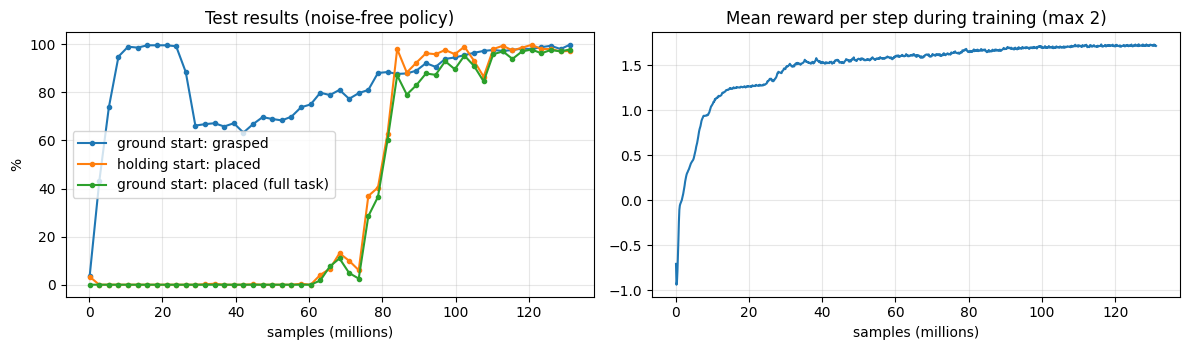

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
x = np.array(history["test_samples"]) / 1e6
axes[0].plot(x, np.array(history["grasped"]) * 100, "-o", ms=3, label="ground start: grasped")
axes[0].plot(x, np.array(history["holding"]) * 100, "-o", ms=3, label="holding start: placed")
axes[0].plot(x, np.array(history["ground"]) * 100, "-o", ms=3, label="ground start: placed (full task)")
axes[0].set_ylabel("%"); axes[0].set_ylim(-5, 105); axes[0].legend(); axes[0].set_title("Test results (noise-free policy)")
axes[1].plot(np.array(history["samples"]) / 1e6, history["reward"]); axes[1].set_title("Mean reward per step during training (max 2)")
for ax in axes:
    ax.set_xlabel("samples (millions)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

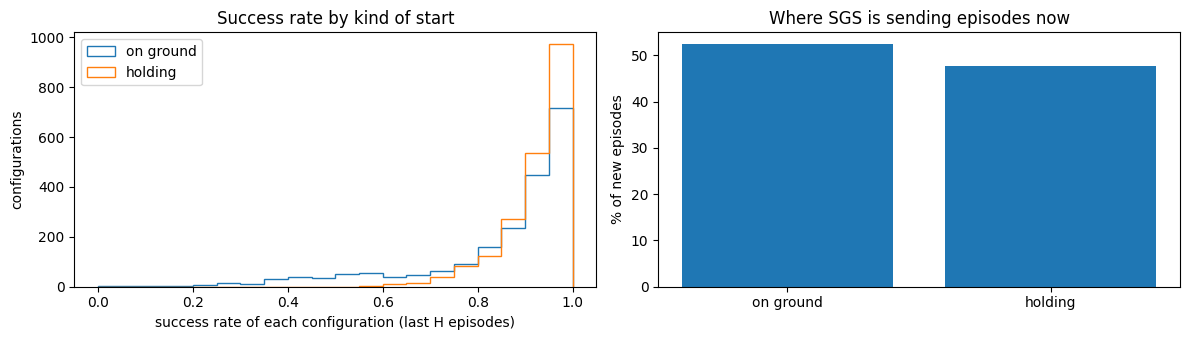

In [14]:
if env.sampler == "sgs":
    p, tried = env.sgs_success_rates().cpu().numpy(), (env.sgs_count > 0).cpu().numpy()
    prob, kind = env.sgs_probs().cpu().numpy(), env.cfg_kind.cpu().numpy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for k, name in enumerate(env.kind_names):
        m = (kind == k) & tried
        if m.any():
            axes[0].hist(p[m], bins=20, range=(0, 1), histtype="step", lw=2, label=name)
    axes[0].set_xlabel("success rate of each configuration (last H episodes)"); axes[0].set_ylabel("configurations")
    axes[0].legend(); axes[0].set_title("Success rate by kind of start")
    share = [prob[kind == k].sum() * 100 for k in range(len(env.kind_names))]
    axes[1].bar(env.kind_names, share); axes[1].set_ylabel("% of new episodes")
    axes[1].set_title("Where SGS is sending episodes now")
    plt.tight_layout(); plt.show()

## 4. Test

**a) Random starts of each kind**, 4096 each.

In [15]:
for name, holding in [("object on the ground", False), ("already holding the object", True)]:
    out = rollout(policy, env, env.sample(4096, torch.full((4096,), holding, device=device)))
    line = f"{name}: placed in {out['success'].mean() * 100:.1f}% of 4096 starts"
    if not holding:
        line += f" (picked it up in {out['ever_held'].mean() * 100:.1f}%)"
    if out["success"].any():
        line += f"; median time to place {np.nanmedian(out['time_placed']):.2f} s"
    print(line)

object on the ground: placed in 97.2% of 4096 starts (picked it up in 99.1%); median time to place 0.88 s
already holding the object: placed in 96.4% of 4096 starts; median time to place 0.66 s


**b) Map over object position and goal position.** Object on the ground, arm starting at rest pointing straight up, 0.2 kg object. Colour is the time until the object is placed; red crosses are failures. Between the dashed lines the goal is closer to the object than anything seen in training.

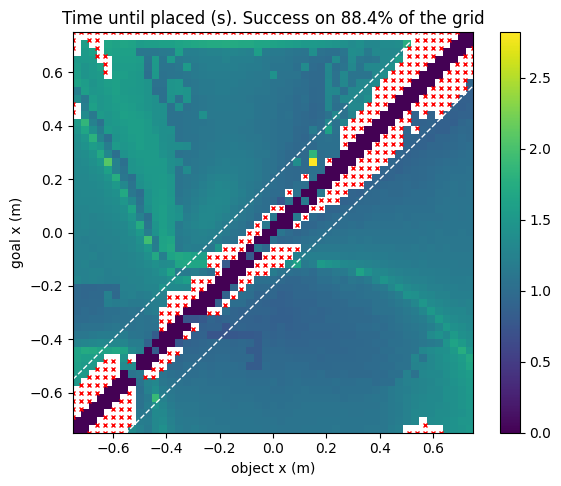

In [16]:
G = 51
xs = torch.linspace(-env.x_range, env.x_range, G, device=device)
OX, GX = torch.meshgrid(xs, xs, indexing="ij")
n = G * G
st = env.sample(n, torch.zeros(n, dtype=torch.bool, device=device), mass=torch.full((n,), 0.2, device=device))
st["q"] = torch.zeros(n, 2 * env.k, device=device)                 # straight up, at rest
st["obj"][:, 0], st["goal_x"] = OX.reshape(-1), GX.reshape(-1)
out = rollout(policy, env, st)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
r = env.x_range
im = ax.imshow(out["time_placed"].reshape(G, G).T, origin="lower", extent=[-r, r, -r, r], cmap="viridis")
fail = ~out["success"]
ax.plot(OX.reshape(-1).cpu().numpy()[fail], GX.reshape(-1).cpu().numpy()[fail], "rx", ms=3)
for off in (-env.min_separation, env.min_separation):
    ax.plot([-r, r], [-r + off, r + off], "w--", lw=1)
ax.set_xlim(-r, r); ax.set_ylim(-r, r)
ax.set_xlabel("object x (m)"); ax.set_ylabel("goal x (m)")
ax.set_title(f"Time until placed (s). Success on {out['success'].mean() * 100:.1f}% of the grid")
fig.colorbar(im, ax=ax); plt.show()

**c) Object mass.** Success on ground starts as the object gets heavier. The shaded band is the mass range used in training.

In [ ]:
masses = np.linspace(0.05, 0.6, 12)
rates = []
for m in masses:
    st = env.sample(1024, torch.zeros(1024, dtype=torch.bool, device=device), mass=torch.full((1024,), float(m), device=device))
    rates.append(rollout(policy, env, st)["success"].mean() * 100)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.axvspan(*env.obj_mass, color="0.9"); ax.plot(masses, rates, "-o")
ax.set_xlabel("object mass (kg)"); ax.set_ylabel("placed (%)"); ax.set_ylim(-5, 105); ax.grid(alpha=0.3)
ax.set_title("Full task success vs object mass"); plt.show()

**d) Animations.** Two arms starting with the object on the ground and one already holding it. The green bar on the ground is the goal zone. Change the seed for different cases.

In [ ]:
torch.manual_seed(3)
st = env.sample(3, torch.tensor([False, False, True], device=device))
out = rollout(policy, env, st)
titles = [("object on ground" if i < 2 else "starts holding") + ("" if ok else "  (failed)") for i, ok in enumerate(out["success"])]
display(animate(out, env, titles=titles))

## Things to try

- **Remove the grip cost** (`grip_cost=0.0`) and watch the policy learn to grasp and carry but never let go: a clear example of a reward that is "correct" yet leaves the policy stuck.
- **Only one kind of start**: set `env.start_holding[:] = False` (or `True`) before training to see how much the mix of starting conditions helps.
- **Heavier objects**: widen `obj_mass`, e.g. `(0.1, 0.5)`. Around 0.5 kg the elbow motor is near its limit with the arm stretched out.
- **Tighter placement**: `tol=0.02`.
- **Hide the mass**: remove the mass from `observe()` and see whether the policy can cope without being told how heavy the object is.
- **Reward ladder**: change the stage values in `advance()` (0.5 / 1.5 / 2.0) and see which stages speed up or stall.